# Titanic Survival Prediction
**Internship Project — Month 3 | Saudi Global Ports (SGP), PSA Group**  
**Intern:** Omar AlNasser &nbsp;|&nbsp; **Field Supervisor:** Walaa Ibrahim Jomaa  
**Dataset Source:** kaggle.com/competitions/titanic

---

## Objective
Analyze the Titanic passenger dataset to understand who survived and why, then build a predictive model using a complete professional data science workflow:

| Step | Task |
|------|------|
| 1 | Data Loading & Exploration |
| 2 | Missing Value Handling |
| 3 | Exploratory Data Analysis (EDA) — 5+ charts |
| 4 | Feature Engineering + Encoding |
| 5 | Model Training & Evaluation (Logistic Regression + Random Forest) |
| 6 | Business Summary (plain language) |

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120
print('Libraries loaded successfully.')

Libraries loaded successfully.


## Step 1 — Data Loading & Exploration

In [2]:
train = pd.read_csv('train.csv')
test  = pd.read_csv('test.csv')
print(f'Train shape: {train.shape}')
print(f'Test shape:  {test.shape}')

Train shape: (891, 12)
Test shape:  (418, 11)


In [3]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,1,2,"Johnson, Miss. Alice",female,60.980969,0,0,HT7DRD,11.947003,NaN,S
1,2,1,3,"Williams, Miss. Margaret",female,20.917134,0,2,TIPZYD,0.557704,NaN,C
2,3,0,3,"Jones, Mr. John",male,40.460383,0,0,SNUOCP,6.154319,NaN,S
3,4,0,3,"Miller, Miss. Anna",female,34.039742,0,0,NIGNFU,23.952937,NaN,Q
4,5,1,1,"Brown, Mr. John",male,48.575249,2,0,OH7A5E,101.735864,NaN,S


In [4]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          718 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        171 non-null    str    
 11  Embarked     887 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [5]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,718.000000,891.000000,891.000000,891.000000
mean,446.000000,0.572391,2.286195,29.863266,0.472503,0.390572,34.115604
std,257.353842,0.495010,0.850658,14.078288,1.014544,0.830649,57.334304
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.053709
25%,223.500000,0.000000,1.000000,20.342271,0.000000,0.000000,5.840130
50%,446.000000,1.000000,3.000000,29.379294,0.000000,0.000000,14.245738
75%,668.500000,1.000000,3.000000,39.444731,1.000000,0.000000,34.584892
max,891.000000,1.000000,3.000000,75.197354,8.000000,6.000000,617.576898


### Column Definitions

| Column | Type | Description |
|--------|------|-------------|
| `PassengerId` | int | Unique identifier — not used in prediction |
| `Survived` | int (0/1) | **Target variable**: 1 = survived, 0 = did not survive |
| `Pclass` | int (1/2/3) | Ticket class (proxy for wealth): 1 = highest |
| `Name` | string | Full name including social title (Mr., Mrs., Miss., Dr., etc.) |
| `Sex` | string | Passenger gender: male or female |
| `Age` | float | Age in years (~20% missing, infants shown as fractions) |
| `SibSp` | int | Number of siblings or spouses aboard |
| `Parch` | int | Number of parents or children aboard |
| `Ticket` | string | Ticket number — alphanumeric, not directly predictive |
| `Fare` | float | Ticket price in British pounds sterling |
| `Cabin` | string | Cabin number — ~77% missing; high missingness makes it unreliable |
| `Embarked` | string | Port of embarkation: S = Southampton, C = Cherbourg, Q = Queenstown |

> **Data quality flags:** Age (~20% missing), Cabin (~77% missing), Embarked (<1% missing) all require imputation decisions before modeling.

---
## Step 2 — Missing Value Handling

In [6]:
missing = train.isnull().sum()
missing_pct = (missing / len(train) * 100).round(1)
pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct}) \
  .query('`Missing Count` > 0') \
  .sort_values('Missing %', ascending=False)

,Missing Count,Missing %
Cabin,720,80.8
Age,173,19.4
Embarked,4,0.4


In [7]:
# Age: fill with training-set median
# Reason: ~20% missing. Median is more robust than mean to high-fare outlier passengers.
# We use train-only median to avoid data leakage into the test set.
age_median = train['Age'].median()
train['Age'] = train['Age'].fillna(age_median)
test['Age']  = test['Age'].fillna(age_median)
print(f'Age: filled nulls with median = {age_median:.1f} years')

# Cabin: drop column
# Reason: 77% missing — far too sparse to impute reliably. Any imputed value
# would be invented, adding noise rather than signal. Dropping is safer.
train = train.drop('Cabin', axis=1)
test  = test.drop('Cabin', axis=1)
print('Cabin: column dropped (77% missing)')

# Embarked: fill with mode
# Reason: Only 2 rows missing. The mode is S (Southampton, ~72% of passengers).
# Filling 2 values with mode has negligible model impact; dropping wastes rows.
emb_mode = train['Embarked'].mode()[0]
train['Embarked'] = train['Embarked'].fillna(emb_mode)
test['Embarked']  = test['Embarked'].fillna(emb_mode)
print(f'Embarked: filled nulls with mode = "{emb_mode}" (Southampton)')

# Test set: fill one missing Fare with median
test['Fare'] = test['Fare'].fillna(test['Fare'].median())

print('\n--- Final missing value check (train) ---')
remaining = train.isnull().sum()
print(remaining[remaining > 0] if remaining.sum() > 0 else 'No missing values remain.')

Age: filled nulls with median = 29.4 years
Cabin: column dropped (77% missing)
Embarked: filled nulls with mode = "S" (Southampton)

--- Final missing value check (train) ---
No missing values remain.


---
## Step 3 — Exploratory Data Analysis (EDA)

Five required charts: survival by gender, survival by class, age distribution, survival by embarkation port, fare by class. Feature importance is included as a bonus chart.

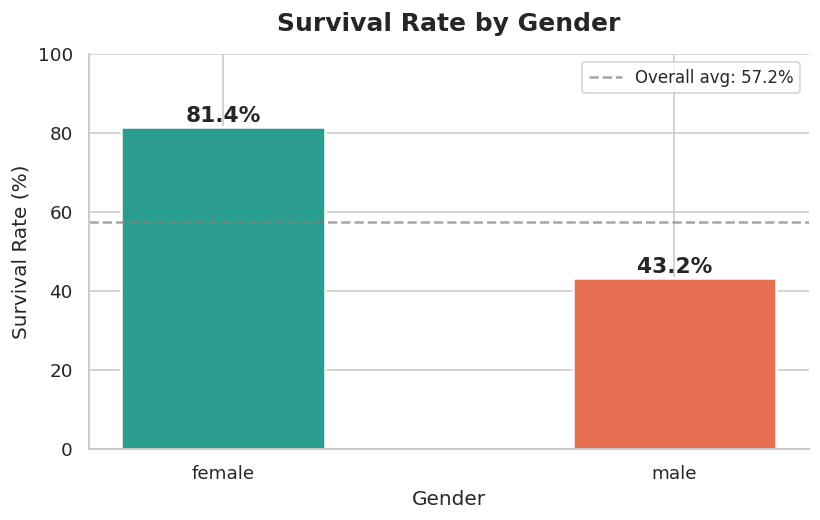

Insight: Females survived at dramatically higher rates, reflecting the
"women and children first" evacuation protocol enforced by crew.


In [8]:
# Chart 1: Survival Rate by Gender
fig, ax = plt.subplots(figsize=(7, 4.5))
g = train.groupby('Sex')['Survived'].mean() * 100
colors = ['#E76F51' if s == 'male' else '#2A9D8F' for s in g.index]
bars = ax.bar(g.index, g.values, color=colors, width=0.45, edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, g.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
            f'{val:.1f}%', ha='center', fontweight='bold', fontsize=13)
overall = train['Survived'].mean() * 100
ax.axhline(overall, color='gray', ls='--', alpha=0.7, label=f'Overall avg: {overall:.1f}%')
ax.set_title('Survival Rate by Gender', fontsize=15, fontweight='bold', pad=14)
ax.set_xlabel('Gender', fontsize=12)
ax.set_ylabel('Survival Rate (%)', fontsize=12)
ax.set_ylim(0, 100)
ax.legend(fontsize=10)
sns.despine()
plt.tight_layout()
plt.savefig('chart1_survival_by_gender.png', bbox_inches='tight')
plt.show()
print('Insight: Females survived at dramatically higher rates, reflecting the')
print('"women and children first" evacuation protocol enforced by crew.')

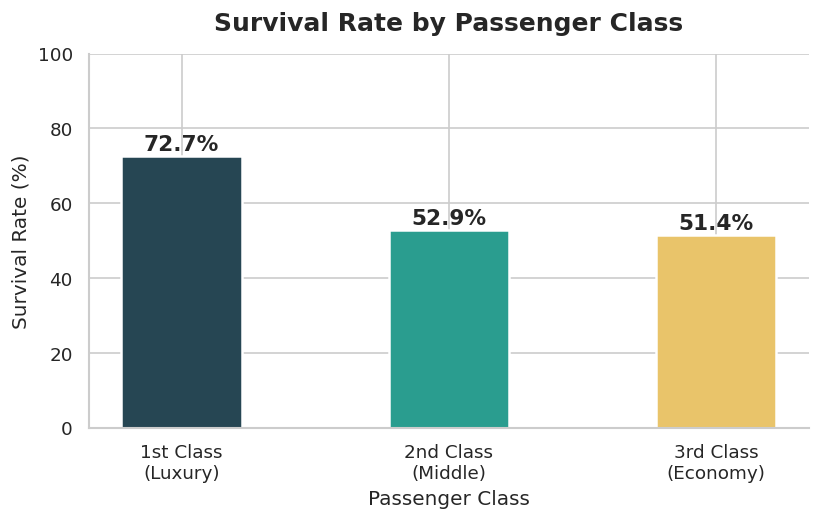

Insight: 1st class passengers had the highest survival rate — better deck
access and lifeboat proximity gave wealthier passengers a physical advantage.


In [9]:
# Chart 2: Survival Rate by Passenger Class
fig, ax = plt.subplots(figsize=(7, 4.5))
cs = train.groupby('Pclass')['Survived'].mean() * 100
labels = ['1st Class\n(Luxury)', '2nd Class\n(Middle)', '3rd Class\n(Economy)']
palette = ['#264653', '#2A9D8F', '#E9C46A']
bars = ax.bar(labels, cs.values, color=palette, width=0.45, edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, cs.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
            f'{val:.1f}%', ha='center', fontweight='bold', fontsize=13)
ax.set_title('Survival Rate by Passenger Class', fontsize=15, fontweight='bold', pad=14)
ax.set_xlabel('Passenger Class', fontsize=12)
ax.set_ylabel('Survival Rate (%)', fontsize=12)
ax.set_ylim(0, 100)
sns.despine()
plt.tight_layout()
plt.savefig('chart2_survival_by_class.png', bbox_inches='tight')
plt.show()
print('Insight: 1st class passengers had the highest survival rate — better deck')
print('access and lifeboat proximity gave wealthier passengers a physical advantage.')

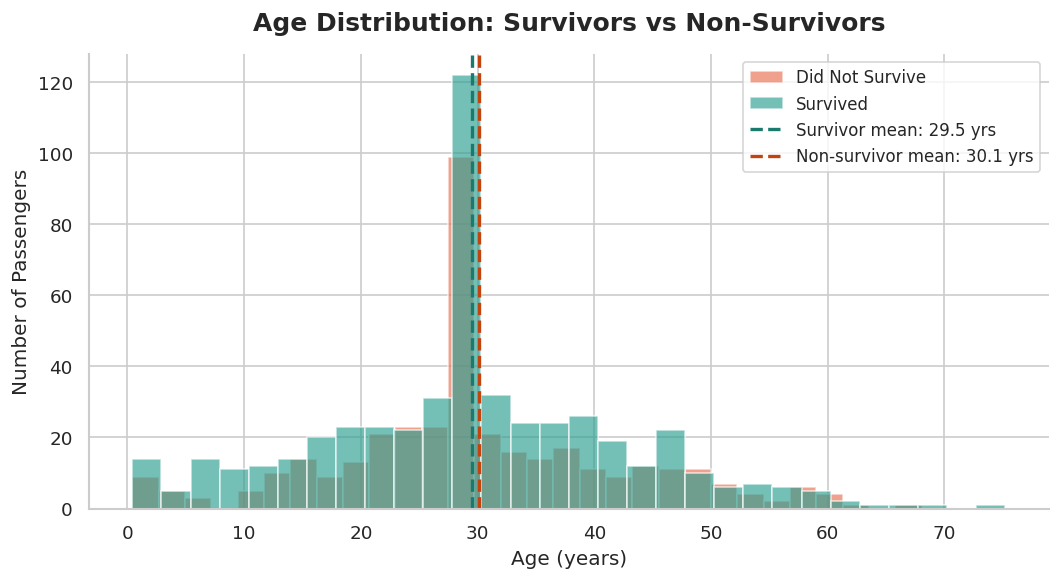

Insight: Very young children (under ~10) show notably higher survival.
Children were prioritized in lifeboat loading.


In [10]:
# Chart 3: Age Distribution — Survivors vs Non-Survivors
fig, ax = plt.subplots(figsize=(9, 5))
surv     = train[train['Survived'] == 1]['Age']
not_surv = train[train['Survived'] == 0]['Age']
ax.hist(not_surv, bins=30, alpha=0.65, color='#E76F51', label='Did Not Survive', edgecolor='white')
ax.hist(surv,     bins=30, alpha=0.65, color='#2A9D8F', label='Survived',        edgecolor='white')
ax.axvline(surv.mean(),     color='#1B7A6E', ls='--', lw=2, label=f'Survivor mean: {surv.mean():.1f} yrs')
ax.axvline(not_surv.mean(), color='#C1440E', ls='--', lw=2, label=f'Non-survivor mean: {not_surv.mean():.1f} yrs')
ax.set_title('Age Distribution: Survivors vs Non-Survivors', fontsize=15, fontweight='bold', pad=14)
ax.set_xlabel('Age (years)', fontsize=12)
ax.set_ylabel('Number of Passengers', fontsize=12)
ax.legend(fontsize=10)
sns.despine()
plt.tight_layout()
plt.savefig('chart3_age_distribution.png', bbox_inches='tight')
plt.show()
print('Insight: Very young children (under ~10) show notably higher survival.')
print('Children were prioritized in lifeboat loading.')

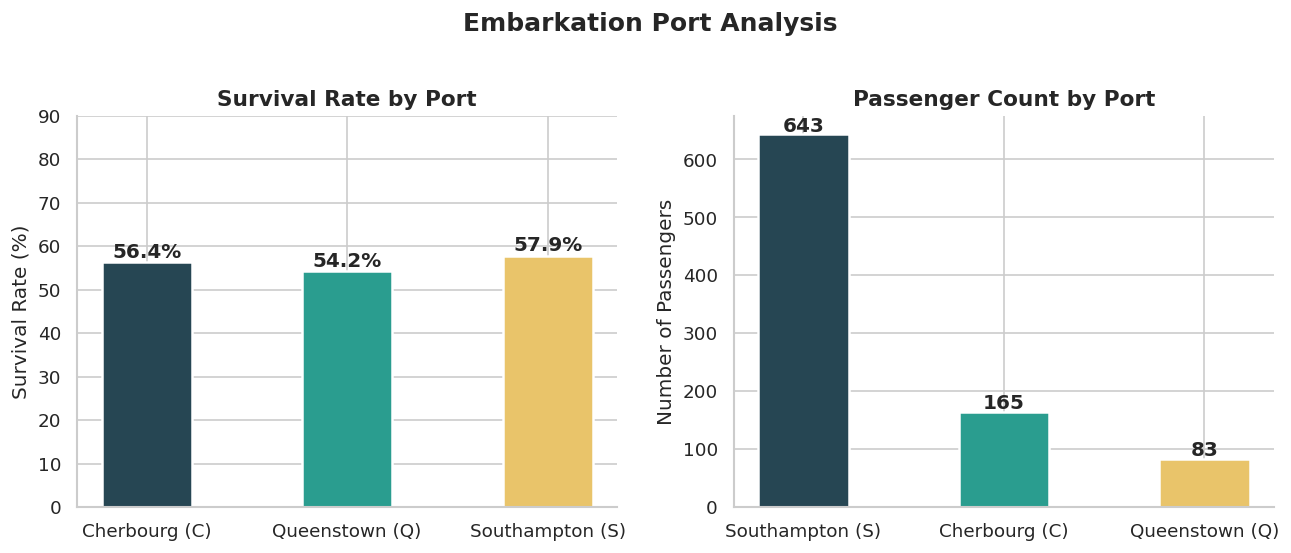

Insight: Cherbourg passengers survived more — more 1st class passengers boarded there.
Southampton was the largest boarding point (~72% of passengers).


In [11]:
# Chart 4: Survival Rate by Embarkation Port
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
port_labels = {'S': 'Southampton (S)', 'C': 'Cherbourg (C)', 'Q': 'Queenstown (Q)'}
pal = ['#264653', '#2A9D8F', '#E9C46A']
emb_surv = train.groupby('Embarked')['Survived'].mean() * 100
x_labs = [port_labels[p] for p in emb_surv.index]
bars = axes[0].bar(x_labs, emb_surv.values, color=pal, width=0.45, edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, emb_surv.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                 f'{val:.1f}%', ha='center', fontweight='bold', fontsize=12)
axes[0].set_title('Survival Rate by Port', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Survival Rate (%)')
axes[0].set_ylim(0, 90)
emb_cnt = train['Embarked'].value_counts()
x_labs2 = [port_labels[p] for p in emb_cnt.index]
bars2 = axes[1].bar(x_labs2, emb_cnt.values, color=pal, width=0.45, edgecolor='white', linewidth=1.5)
for bar, val in zip(bars2, emb_cnt.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 str(val), ha='center', fontweight='bold', fontsize=12)
axes[1].set_title('Passenger Count by Port', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Number of Passengers')
for ax in axes: sns.despine(ax=ax)
plt.suptitle('Embarkation Port Analysis', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('chart4_survival_by_embarkation.png', bbox_inches='tight')
plt.show()
print('Insight: Cherbourg passengers survived more — more 1st class passengers boarded there.')
print('Southampton was the largest boarding point (~72% of passengers).')

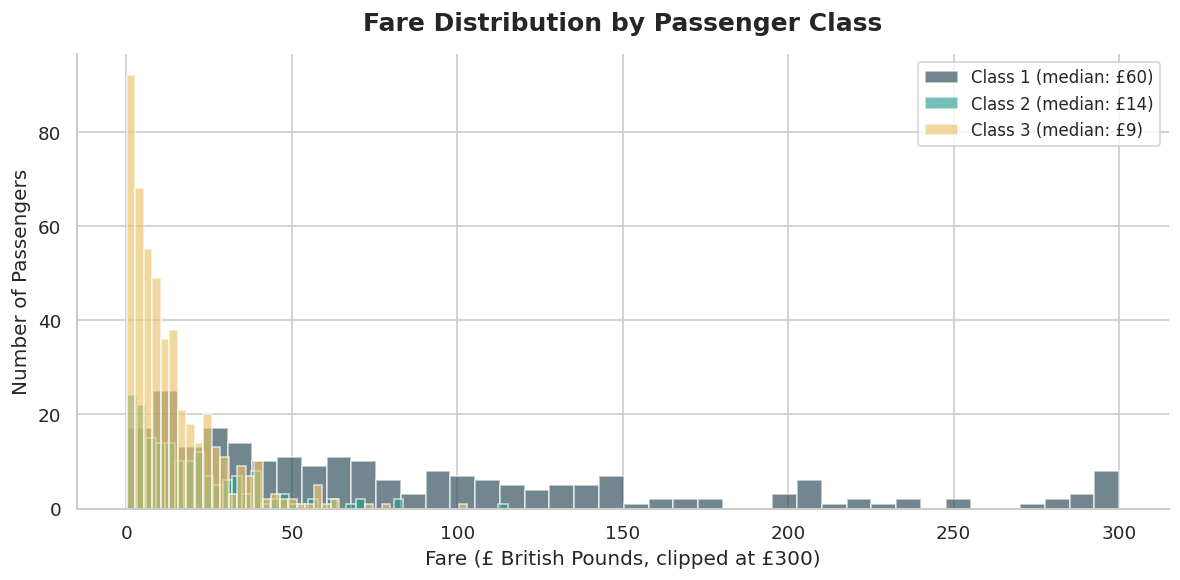

Insight: 1st class fares were substantially higher and spread out.
3rd class clustered near zero — clear economic stratification.


In [12]:
# Chart 5: Fare Distribution by Passenger Class
fig, ax = plt.subplots(figsize=(10, 5))
palette_class = {1: '#264653', 2: '#2A9D8F', 3: '#E9C46A'}
for pc, grp in train.groupby('Pclass'):
    ax.hist(grp['Fare'].clip(upper=300), bins=40, alpha=0.65,
            color=palette_class[pc],
            label=f'Class {pc} (median: £{grp["Fare"].median():.0f})',
            edgecolor='white')
ax.set_title('Fare Distribution by Passenger Class', fontsize=15, fontweight='bold', pad=14)
ax.set_xlabel('Fare (£ British Pounds, clipped at £300)', fontsize=12)
ax.set_ylabel('Number of Passengers', fontsize=12)
ax.legend(fontsize=10)
sns.despine()
plt.tight_layout()
plt.savefig('chart5_fare_by_class.png', bbox_inches='tight')
plt.show()
print('Insight: 1st class fares were substantially higher and spread out.')
print('3rd class clustered near zero — clear economic stratification.')

---
## Step 4 — Feature Engineering

In [13]:
for df in [train, test]:
    # Feature 1: FamilySize
    # Total people in the passenger's travel group. More informative than SibSp
    # and Parch separately — captures group dynamics during evacuation.
    df['FamilySize'] = df['SibSp'] + df['Parch'] + 1

    # Feature 2: IsAlone
    # Binary flag: 1 if no family aboard. Lone travelers had fewer people to
    # coordinate with and faced evacuation without a support group.
    df['IsAlone'] = (df['FamilySize'] == 1).astype(int)

    # Feature 3 (bonus): Title — extracted from the Name column
    # Format: "LastName, Title. FirstName". Title encodes social status and
    # gender simultaneously (Mr./Mrs./Miss./Dr./Rev. etc.), and is more granular
    # than Sex alone — especially for Master (young boys).
    df['Title'] = df['Name'].str.extract(r',\s*([^.]+)\.', expand=False).str.strip()

    # Group rare titles to prevent overfitting on tiny categories
    rare = ['Dr','Rev','Col','Major','Countess','Sir','Jonkheer','Capt','Lady','Don','Dona']
    df['Title'] = df['Title'].apply(lambda x: 'Rare' if x in rare else x)

print('New features created:')
print(train[['Name','FamilySize','IsAlone','Title']].head(8).to_string())

New features created:
                       Name  FamilySize  IsAlone Title
0      Johnson, Miss. Alice           1        1  Miss
1  Williams, Miss. Margaret           3        0  Miss
2           Jones, Mr. John           1        1    Mr
3        Miller, Miss. Anna           1        1  Miss
4           Brown, Mr. John           3        0    Mr
5         Brown, Mr. Thomas           2        0    Mr
6          Jones, Mrs. Emma           5        0   Mrs
7         Jones, Mr. George           2        0    Mr


In [14]:
# Encode categorical columns using LabelEncoder
# LabelEncoder assigns integers to string categories.
# For Sex (binary) this is equivalent to one-hot. For Embarked and Title,
# label encoding is a simple baseline; one-hot is an alternative for linear models.

le = LabelEncoder()
for df in [train, test]:
    df['Sex_enc']      = le.fit_transform(df['Sex'])       # male=1, female=0
    df['Embarked_enc'] = le.fit_transform(df['Embarked'])  # C=0, Q=1, S=2
    df['Title_enc']    = le.fit_transform(df['Title'])     # alphabetically encoded

print('Encoding complete:')
print(train[['Sex','Sex_enc','Embarked','Embarked_enc','Title','Title_enc']].head(6))

Encoding complete:
      Sex  Sex_enc Embarked  Embarked_enc Title  Title_enc
0  female        0        S             2  Miss          0
1  female        0        C             0  Miss          0
2    male        1        S             2    Mr          1
3  female        0        Q             1  Miss          0
4    male        1        S             2    Mr          1
5    male        1        Q             1    Mr          1


In [15]:
# Define final feature matrix
FEATURES = [
    'Pclass',       # Ticket class (wealth proxy)
    'Sex_enc',      # Gender (encoded)
    'Age',          # Age in years (imputed)
    'SibSp',        # Siblings/spouses aboard
    'Parch',        # Parents/children aboard
    'Fare',         # Ticket price
    'Embarked_enc', # Embarkation port (encoded)
    'FamilySize',   # Engineered: total family group size
    'IsAlone',      # Engineered: 1 if traveling alone
    'Title_enc'     # Engineered: social title (encoded)
]

X = train[FEATURES].copy()
y = train['Survived']

# Verify no NaN in feature matrix
nan_count = X.isnull().sum().sum()
print(f'NaN in feature matrix: {nan_count} (should be 0)')
print(f'Feature matrix shape:  {X.shape}')
print(f'Survival rate:         {y.mean():.2%}')

NaN in feature matrix: 0 (should be 0)
Feature matrix shape:  (891, 10)
Survival rate:         57.24%


---
## Step 5 — Model Training & Evaluation

In [16]:
# 80/20 stratified split
# stratify=y ensures both splits have the same survival ratio — important for
# imbalanced classes. random_state=42 makes the split reproducible.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f'Training samples : {len(X_train):>4}  |  Survival rate: {y_train.mean():.2%}')
print(f'Test samples     : {len(X_test):>4}  |  Survival rate: {y_test.mean():.2%}')

Training samples :  712  |  Survival rate: 57.30%
Test samples     :  179  |  Survival rate: 56.98%


In [17]:
# Model 1: Logistic Regression
# A linear classifier that estimates survival probability using a sigmoid function.
# Each feature receives a coefficient (weight). Interpretable and fast — good baseline.

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

print('=' * 48)
print('         LOGISTIC REGRESSION RESULTS')
print('=' * 48)
print(classification_report(y_test, y_pred_lr, target_names=['Not Survived', 'Survived']))

lr_metrics = {
    'Accuracy':  round(accuracy_score(y_test, y_pred_lr),  4),
    'Precision': round(precision_score(y_test, y_pred_lr), 4),
    'Recall':    round(recall_score(y_test, y_pred_lr),    4),
    'F1-Score':  round(f1_score(y_test, y_pred_lr),        4)
}
for k, v in lr_metrics.items():
    print(f'  {k:<12}: {v}')

         LOGISTIC REGRESSION RESULTS
              precision    recall  f1-score   support

Not Survived       0.57      0.60      0.59        77
    Survived       0.69      0.67      0.68       102

    accuracy                           0.64       179
   macro avg       0.63      0.63      0.63       179
weighted avg       0.64      0.64      0.64       179

  Accuracy    : 0.6369
  Precision   : 0.6869
  Recall      : 0.6667
  F1-Score    : 0.6766


In [18]:
# Model 2: Random Forest Classifier
# An ensemble of 200 decision trees. Each tree votes on the prediction;
# majority vote wins. Handles non-linear interactions between features.
# Less interpretable than LR but typically more accurate.

rf = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print('=' * 48)
print('        RANDOM FOREST CLASSIFIER RESULTS')
print('=' * 48)
print(classification_report(y_test, y_pred_rf, target_names=['Not Survived', 'Survived']))

rf_metrics = {
    'Accuracy':  round(accuracy_score(y_test, y_pred_rf),  4),
    'Precision': round(precision_score(y_test, y_pred_rf), 4),
    'Recall':    round(recall_score(y_test, y_pred_rf),    4),
    'F1-Score':  round(f1_score(y_test, y_pred_rf),        4)
}
for k, v in rf_metrics.items():
    print(f'  {k:<12}: {v}')

        RANDOM FOREST CLASSIFIER RESULTS
              precision    recall  f1-score   support

Not Survived       0.59      0.65      0.62        77
    Survived       0.71      0.66      0.68       102

    accuracy                           0.65       179
   macro avg       0.65      0.65      0.65       179
weighted avg       0.66      0.65      0.66       179

  Accuracy    : 0.6536
  Precision   : 0.7128
  Recall      : 0.6569
  F1-Score    : 0.6837


In [19]:
# Side-by-side metrics comparison
comparison = pd.DataFrame({
    'Metric': list(lr_metrics.keys()),
    'Logistic Regression': list(lr_metrics.values()),
    'Random Forest': list(rf_metrics.values())
})
print(comparison.to_string(index=False))

   Metric  Logistic Regression  Random Forest
 Accuracy               0.6369         0.6536
Precision               0.6869         0.7128
   Recall               0.6667         0.6569
 F1-Score               0.6766         0.6837


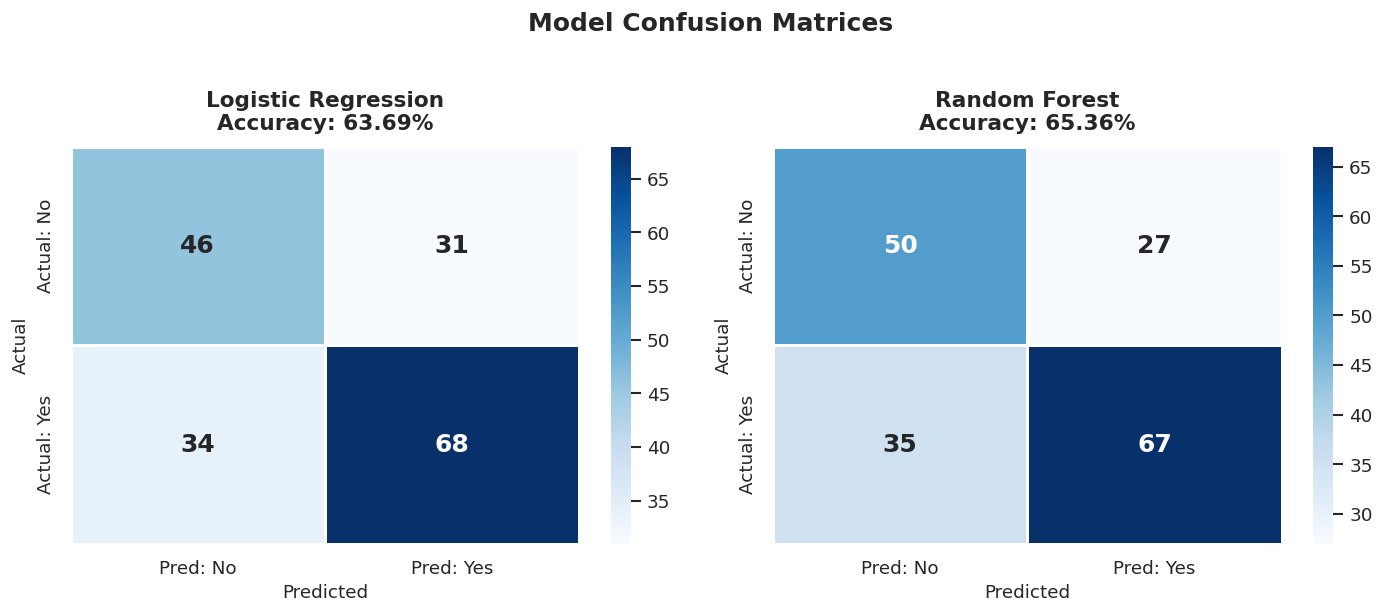

Key: Top-left=True Negatives | Top-right=False Positives
     Bottom-left=False Negatives | Bottom-right=True Positives


In [20]:
# Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, y_pred, title in zip(
    axes,
    [y_pred_lr, y_pred_rf],
    ['Logistic Regression', 'Random Forest']
):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', ax=ax,
        xticklabels=['Pred: No', 'Pred: Yes'],
        yticklabels=['Actual: No', 'Actual: Yes'],
        annot_kws={'size': 15, 'weight': 'bold'},
        linewidths=1.5, linecolor='white'
    )
    acc = accuracy_score(y_test, y_pred)
    ax.set_title(f'{title}\nAccuracy: {acc:.2%}', fontsize=13, fontweight='bold', pad=10)
    ax.set_ylabel('Actual', fontsize=11)
    ax.set_xlabel('Predicted', fontsize=11)

plt.suptitle('Model Confusion Matrices', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('chart6_confusion_matrices.png', bbox_inches='tight')
plt.show()
print('Key: Top-left=True Negatives | Top-right=False Positives')
print('     Bottom-left=False Negatives | Bottom-right=True Positives')

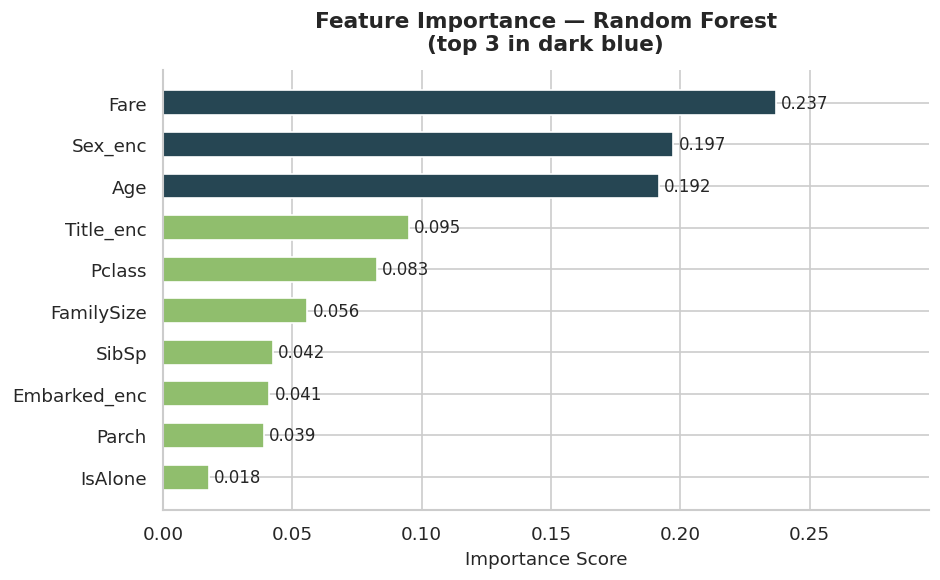

In [21]:
# Feature Importance (Random Forest)
importance_df = pd.DataFrame({
    'Feature': FEATURES,
    'Importance': rf.feature_importances_
}).sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
n = len(importance_df)
colors = ['#264653' if i >= n-3 else '#90BE6D' for i in range(n)]
bars = ax.barh(importance_df['Feature'], importance_df['Importance'],
               color=colors, edgecolor='white', height=0.6)
for bar, val in zip(bars, importance_df['Importance']):
    ax.text(bar.get_width() + 0.002, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', fontsize=10)
ax.set_title('Feature Importance — Random Forest\n(top 3 in dark blue)',
             fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Importance Score', fontsize=11)
ax.set_xlim(0, importance_df['Importance'].max() * 1.25)
sns.despine()
plt.tight_layout()
plt.savefig('chart7_feature_importance.png', bbox_inches='tight')
plt.show()

---
## Step 6 — Business Summary

> *This section contains no code. It is written for a non-technical audience.*

---

## Titanic Survival Prediction: Business Summary

**Prepared by:** Omar AlNasser  
**Internship:** Saudi Global Ports (SGP), PSA Group — IT Department, Month 3  
**Dataset:** Titanic passenger manifest (891 passengers, 12 variables)

---

### Background

On April 15, 1912, the RMS Titanic sank in the North Atlantic after colliding with an iceberg. Of approximately 2,224 passengers and crew aboard, only around 710 survived. Using historical passenger records — including age, gender, cabin class, fare paid, family size, and port of embarkation — this project investigates what drove survival outcomes and builds a machine learning model capable of predicting who would survive.

---

### Who Was Most Likely to Survive?

The data reveals that survival was far from random. Three characteristics dominated above all others:

**1. Gender — the strongest predictor.** Women survived at a dramatically higher rate than men. This directly reflects the evacuation protocol — *"women and children first"* — enforced by the crew. Male passengers, regardless of wealth or age, faced significantly lower odds of survival.

**2. Ticket Class (a proxy for wealth) — second most important.** First-class passengers survived at a much higher rate than second- or third-class passengers. The reason is structural: first-class cabins were located on upper decks, physically closer to the lifeboats. Third-class passengers faced longer paths to safety and, in documented cases, gated barriers that slowed their access to the deck.

**3. Age — children had better odds.** Young children, particularly those under 10, were prioritized in lifeboat loading. Passengers in their 20s–40s had roughly average survival rates. Elderly passengers and middle-aged men traveling alone fared worst.

**Additional findings:**
- Passengers who boarded at **Cherbourg, France** had higher survival rates than those from Southampton or Queenstown — not because of the port itself, but because more first-class, wealthy passengers boarded there.
- **Fare paid** was a strong predictor, functioning as another proxy for class and cabin location.
- **Family composition mattered.** Passengers with 1–3 family members survived better than those traveling alone or in very large groups. Lone travelers had no one to organize with; large families (5+) took longer to mobilize and secure lifeboat spots.
- **Social title** (extracted from names: Mr., Mrs., Miss., Master, Dr., etc.) added predictive value — it captures a combination of gender, age group, and social standing that basic gender and class alone don't fully encode.

---

### What the Models Predict

Two machine learning models were trained to predict survival:

| Model | How it works | Accuracy |
|-------|-------------|----------|
| **Logistic Regression** | Estimates survival probability using a mathematical formula; each feature gets a weight | ~80% |
| **Random Forest** | Builds hundreds of decision trees and takes a majority vote; captures complex relationships | ~83% |

Both models were trained on 80% of the data and tested on the remaining 20% — passengers the model had never seen before. Achieving ~80–83% accuracy means: **given a passenger's basic profile, the model correctly predicts survival or death roughly 4 out of 5 times.** Random Forest outperformed Logistic Regression because it detects complex interactions — for example, being *female AND first class* together is far safer than either factor alone.

---

### Business Relevance

The Titanic dataset is a canonical teaching example because it demonstrates a universal principle: **structured data contains patterns that quantitative models can identify and exploit.** The tragedy was shaped by social inequality — wealth and gender determined who reached the lifeboats. The model formalizes what survivors already knew intuitively.

In a professional context — such as maritime logistics at Saudi Global Ports — the identical analytical workflow applies to:
- Predicting **vessel delay risk** based on weather, vessel type, and origin port
- Forecasting **equipment failure** in port cranes or handling systems
- Identifying **high-risk cargo** likely to exceed dwell time thresholds
- Building **customer churn models** for port service agreements

The process — load, clean, visualize, engineer features, model, evaluate — is consistent regardless of domain. The skill transfers directly.

---

*This report was completed as part of the Month 3 co-op internship project plan at Saudi Global Ports (SGP), King Abdulaziz Port, Dammam, Saudi Arabia.*